# Movie Recommendation Insights Using Python

**Approach:** Content-Based Movie Recommendation

**Techniques:** TF-IDF Vectorization + Cosine Similarity

This notebook uses the selected `movies.csv` dataset to inspect movie metadata, perform basic preprocessing, analyse genres, and recommend movies similar to a selected movie.

## 1. Import Required Libraries

In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

## 2. Load the Dataset

Upload `movies.csv` in Google Colab, then run the following cell.

In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("movies.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()

Saving movies.csv to movies.csv
Dataset loaded successfully.
Shape: (62423, 3)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## 3. Initial Dataset Inspection

In [ ]:
print("Columns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nDuplicate movie IDs:", df["movieId"].duplicated().sum())

Columns: ['movieId', 'title', 'genres']

Data types:
movieId     int64
title      object
genres     object
dtype: object

Missing values:
movieId    0
title      0
genres     0
dtype: int64

Duplicate rows: 0

Duplicate movie IDs: 0


## 4. Data Cleaning and Preprocessing

In [ ]:
df = df.drop_duplicates(subset="movieId").copy()
df["title"] = df["title"].fillna("").astype(str).str.strip()
df["genres"] = df["genres"].fillna("").astype(str).str.strip()

df = df[df["title"] != ""].copy()

# Extract release year from titles such as "Toy Story (1995)"
def extract_year(title):
    match = re.search(r"\((\d{4})\)\s*$", title)
    return int(match.group(1)) if match else pd.NA

df["year"] = df["title"].apply(extract_year).astype("Int64")

# Convert pipe-separated genres into a text representation for TF-IDF
df["genre_features"] = (
    df["genres"]
    .str.replace("|", " ", regex=False)
    .str.replace("(no genres listed)", "", regex=False)
    .str.lower()
    .str.strip()
)

print("Prepared dataset shape:", df.shape)
df.head()

Prepared dataset shape: (62423, 5)


,movieId,title,genres,year,genre_features
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,adventure animation children comedy fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,adventure children fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,comedy romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995,comedy drama romance
4,5,Father of the Bride Part II (1995),Comedy,1995,comedy


## 5. Exploratory Genre Analysis

In [ ]:
genre_counts = (
    df["genres"]
    .str.split("|")
    .explode()
    .value_counts()
)

print("Top 15 genres:")
print(genre_counts.head(15))

Top 15 genres:
genres
Drama                 25606
Comedy                16870
Thriller               8654
Romance                7719
Action                 7348
Horror                 5989
Documentary            5605
Crime                  5319
(no genres listed)     5062
Adventure              4145
Sci-Fi                 3595
Children               2935
Animation              2929
Mystery                2925
Fantasy                2731
Name: count, dtype: int64


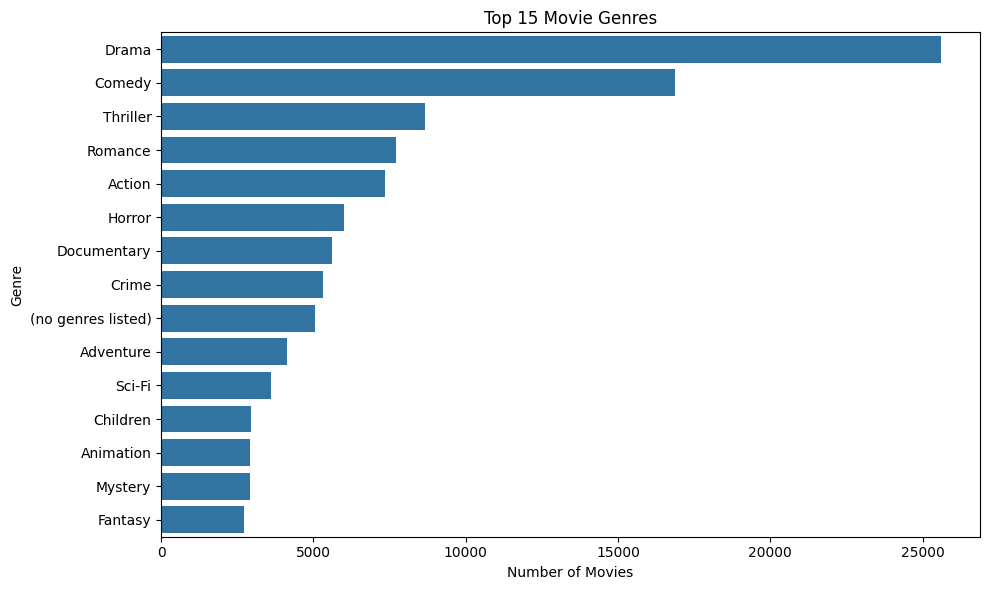

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(x=genre_counts.head(15).values, y=genre_counts.head(15).index)
plt.title("Top 15 Movie Genres")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

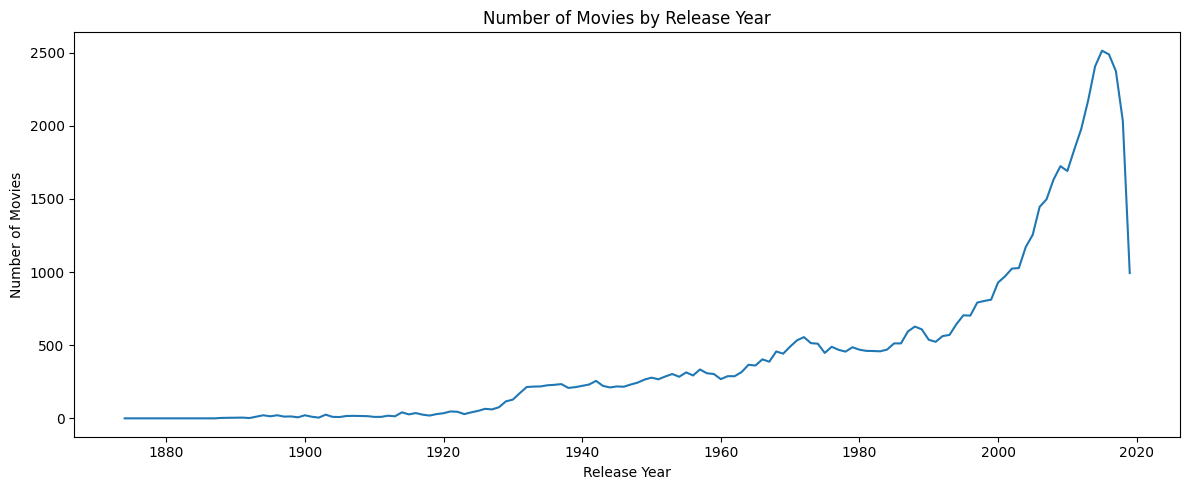

In [ ]:
year_counts = df["year"].dropna().value_counts().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(year_counts.index, year_counts.values)
plt.title("Number of Movies by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

## 6. TF-IDF Feature Representation

The movie genres are converted into numerical feature vectors. TF-IDF gives different weights to genre terms based on their occurrence across the dataset.

In [ ]:
vectorizer = TfidfVectorizer(token_pattern=r"(?u)\b[\w-]+\b")
tfidf_matrix = vectorizer.fit_transform(df["genre_features"])

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of genre features:", len(vectorizer.get_feature_names_out()))

TF-IDF matrix shape: (62423, 19)
Number of genre features: 19


## 7. Cosine Similarity and Recommendation Function

For a selected movie, cosine similarity compares its genre vector with all other movie vectors. The movies with the highest similarity scores are returned as recommendations.

In [ ]:
def recommend_movies(movie_title, n=10):
    query = movie_title.strip()

    # Exact title match
    matches = df.index[df["title"].str.lower() == query.lower()].tolist()

    # Partial match if exact title is not found
    if not matches:
        partial = df[df["title"].str.lower().str.contains(query.lower(), regex=False)]
        if partial.empty:
            raise ValueError(f"Movie '{movie_title}' was not found in the dataset.")
        matches = [partial.index[0]]

    movie_idx = matches[0]
    row_position = df.index.get_loc(movie_idx)
    query_year = df.iloc[row_position]["year"]

    query_vector = tfidf_matrix[row_position]
    scores = cosine_similarity(query_vector, tfidf_matrix).ravel()

    # Primary ranking: cosine similarity.
    # Tie-breaker: release-year proximity, so equally similar movies
    # are presented in a more relevant order.
    candidates = []
    for pos, score in enumerate(scores):
        if pos == row_position:
            continue

        candidate_year = df.iloc[pos]["year"]
        if pd.notna(query_year) and pd.notna(candidate_year):
            year_distance = abs(int(candidate_year) - int(query_year))
        else:
            year_distance = float("inf")

        candidates.append((pos, float(score), year_distance))

    candidates.sort(key=lambda x: (-x[1], x[2]))

    results = []
    for pos, score, _ in candidates[:n]:
        results.append({
            "title": df.iloc[pos]["title"],
            "genres": df.iloc[pos]["genres"],
            "year": df.iloc[pos]["year"],
            "similarity": round(score, 4)
        })

    return pd.DataFrame(results)


## 8. Test the Recommendation System

In [ ]:
recommend_movies("Toy Story (1995)", 10)

,title,genres,year,similarity
0,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1998,1.0
1,Aladdin (1992),Adventure|Animation|Children|Comedy|Fantasy,1992,1.0
2,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1999,1.0
3,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,2000,1.0
4,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,2000,1.0
5,DuckTales: The Movie - Treasure of the Lost La...,Adventure|Animation|Children|Comedy|Fantasy,1990,1.0
6,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,2001,1.0
7,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,2006,1.0
8,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy,2006,1.0
9,Brother Bear 2 (2006),Adventure|Animation|Children|Comedy|Fantasy,2006,1.0


In [ ]:
recommend_movies("Jumanji (1995)", 10)

,title,genres,year,similarity
0,"Indian in the Cupboard, The (1995)",Adventure|Children|Fantasy,1995,1.0
1,Magic in the Water (1995),Adventure|Children|Fantasy,1995,1.0
2,Escape to Witch Mountain (1995),Adventure|Children|Fantasy,1995,1.0
3,"NeverEnding Story III, The (1994)",Adventure|Children|Fantasy,1994,1.0
4,Gulliver's Travels (1996),Adventure|Children|Fantasy,1996,1.0
5,The Cave of the Golden Rose 5 (1996),Adventure|Children|Fantasy,1996,1.0
6,Paws (1997),Adventure|Children|Fantasy,1997,1.0
7,Little Ghost (1997),Adventure|Children|Fantasy,1997,1.0
8,"Polar Bear King, The (Kvitebjørn Kong Valemon)...",Adventure|Children|Fantasy,1991,1.0
9,The Cave of the Golden Rose (1991),Adventure|Children|Fantasy,1991,1.0


In [ ]:
recommend_movies("Heat (1995)", 10)

,title,genres,year,similarity
0,Assassins (1995),Action|Crime|Thriller,1995,1.0
1,Die Hard: With a Vengeance (1995),Action|Crime|Thriller,1995,1.0
2,"Net, The (1995)",Action|Crime|Thriller,1995,1.0
3,Crying Freeman (1995),Action|Crime|Thriller,1995,1.0
4,Night of the Running Man (1995),Action|Crime|Thriller,1995,1.0
5,Natural Born Killers (1994),Action|Crime|Thriller,1994,1.0
6,Once a Thief (1996),Action|Crime|Thriller,1996,1.0
7,Judgment Night (1993),Action|Crime|Thriller,1993,1.0
8,Mean Guns (1997),Action|Crime|Thriller,1997,1.0
9,No Contest II (1997),Action|Crime|Thriller,1997,1.0


## 9. Interactive Recommendation

Enter a movie title from the dataset.

In [ ]:
movie_name = input("Enter a movie title: ")

try:
    recommendations = recommend_movies(movie_name, 10)
    print(f"\nRecommendations for: {movie_name}")
    display(recommendations)
except ValueError as e:
    print(e)

Enter a movie title: Waiting to Exhale

Recommendations for: Waiting to Exhale


,title,genres,year,similarity
0,"American President, The (1995)",Comedy|Drama|Romance,1995,1.0
1,Mighty Aphrodite (1995),Comedy|Drama|Romance,1995,1.0
2,Something to Talk About (1995),Comedy|Drama|Romance,1995,1.0
3,Don Juan DeMarco (1995),Comedy|Drama|Romance,1995,1.0
4,"Month by the Lake, A (1995)",Comedy|Drama|Romance,1995,1.0
5,Across the Moon (1995),Comedy|Drama|Romance,1995,1.0
6,Everything Will Be All Right (1995),Comedy|Drama|Romance,1995,1.0
7,Linda Sara (1995),Comedy|Drama|Romance,1995,1.0
8,"Postman, The (Postino, Il) (1994)",Comedy|Drama|Romance,1994,1.0
9,Beautiful Girls (1996),Comedy|Drama|Romance,1996,1.0


## 10. Initial Interpretation

The recommender is a content-based system. It uses the selected movie's genre information to calculate TF-IDF vectors and cosine similarity with other movies.

The recommendation ranking uses **cosine similarity as the primary criterion**. When several movies have the same similarity score, **release-year proximity is used only as a tie-breaker**. This helps make the output more useful without changing the main genre-based recommendation approach.

A similarity score closer to 1 indicates a stronger match in the current genre-based feature representation.

**Important limitation:** The dataset does not contain user ratings, user profiles, or watch history, so this is not a personalized collaborative-filtering system.
